In [91]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
%pip install openpyxl
path = "data/data.xlsx"   # подставьте точное имя файла из папки data
users = pd.read_excel(path, sheet_name="Пользователи")
payments = pd.read_excel(path, sheet_name="Платежи")


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


****EDA****

In [3]:
#Функция первичного скана датасета
def initial_scan(df, df_name):
    print(f"Initial scan of {df_name}:")
    print(f"View:")
    display(df.head())
    print(f"Shape: {df.shape}")
    print(f"Data types:\n")
    display(df.dtypes.reset_index().rename(columns={'index': 'Column', 0: 'Data Type'}))
    print(f"\n Quantity of Missing values:\n")
    display(df.isna().sum().reset_index().rename(columns={'index': 'Column', 0: 'Missing Values'}))
    print(f"\nQuantity of duplicated rows: {df.duplicated().sum()} ")

**Таблица `users`**

In [4]:
#первичный скан
initial_scan(users, "Users")

Initial scan of Users:
View:


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


Shape: (1504, 5)
Data types:



,Column,Data Type
0,user_id,int64
1,group,object
2,age,int64
3,city,object
4,device_type,object



 Quantity of Missing values:



,Column,Missing Values
0,user_id,0
1,group,1
2,age,0
3,city,1
4,device_type,0



Quantity of duplicated rows: 0 


**Пройдемся по каждому признаку**

*user_id:*

In [5]:
#user_id
users.user_id.agg(['min', 'max'])

min    1001
max    9004
Name: user_id, dtype: int64

Посмотрим, нет ли выбросов по id:

In [6]:
ids = users['user_id'].sort_values()
ids[ids > 2490].to_frame()

,user_id
1490,2491
1491,2492
1492,2493
1493,2494
1494,2495
1495,2496
1496,2497
1497,2498
1498,2499
1499,2500


**id идут последовательно, начиная с 1001, но есть аномальные 4 id в диапозоне 9001-9004**

*group:*

In [7]:
users.group.value_counts()

group
A    752
B    751
Name: count, dtype: int64

**Признак *group* категориальный, имеет 2 зн-я 'A' и 'B', как предполагалось, но имеется один пропуск**

*age:*

In [8]:
users.age.describe().to_frame()

,age
count,1504.000000
mean,32.745346
std,8.410915
min,-5.000000
25%,27.000000
50%,33.000000
75%,38.000000
max,150.000000


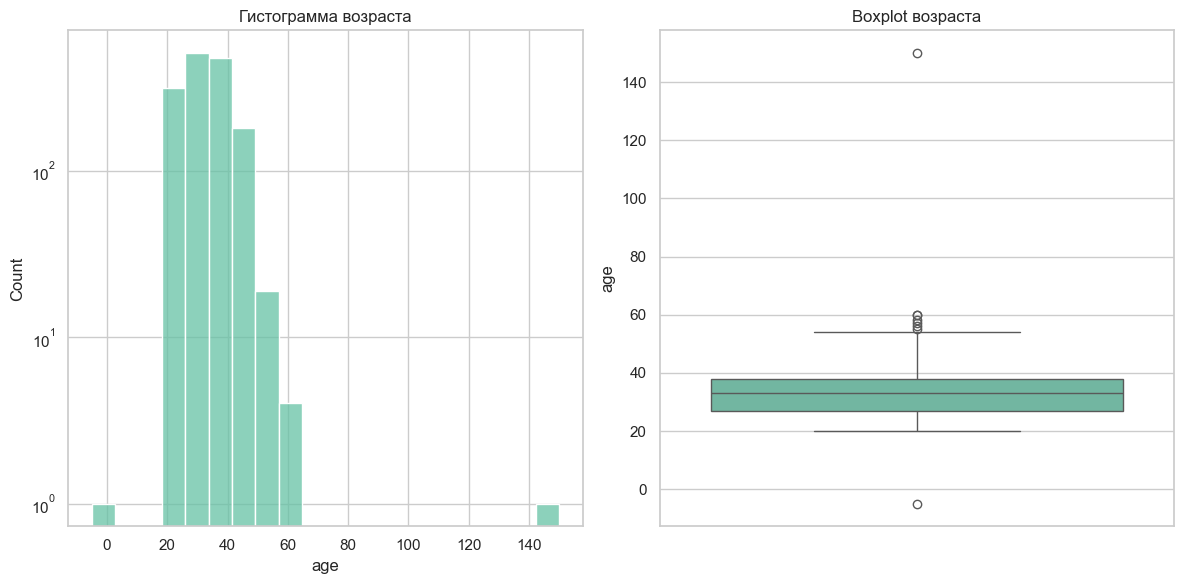

In [9]:
sns.set_theme(style="whitegrid", palette="Set2")
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
sns.histplot(data=users, x='age', bins=20, ax=ax[0])
ax[0].set_yscale('log')
ax[0].set_title("Гистограмма возраста")

sns.boxplot(data=users, y='age', ax=ax[1])
ax[1].set_title("Boxplot возраста")

plt.tight_layout()
plt.show()


**Основная масса пользователей в возрасте от 20 до 60 лет, медиана 33 года, межквартильный размах примерно 27-38. Распределение немного скошено вправо. На гистограмме и на boxplot видны два аномальных значения: -5 и 150 лет. Они физически невозможны, поэтому это ошибки данных, и такие записи будут удалены. Точки около 55-60 лет boxplot тоже помечает как выбросы по правилу 1,5 IQR, но это реальный возраст, поэтому они остаются. Для отсечения использовано окно 14-100 лет. Оно убирает только две заведомо некорректные записи и не затрагивает остальных.**

*city:*

In [10]:
users.city.value_counts().to_frame()

,count
city,
Москва,595
Регион,514
СПб,394


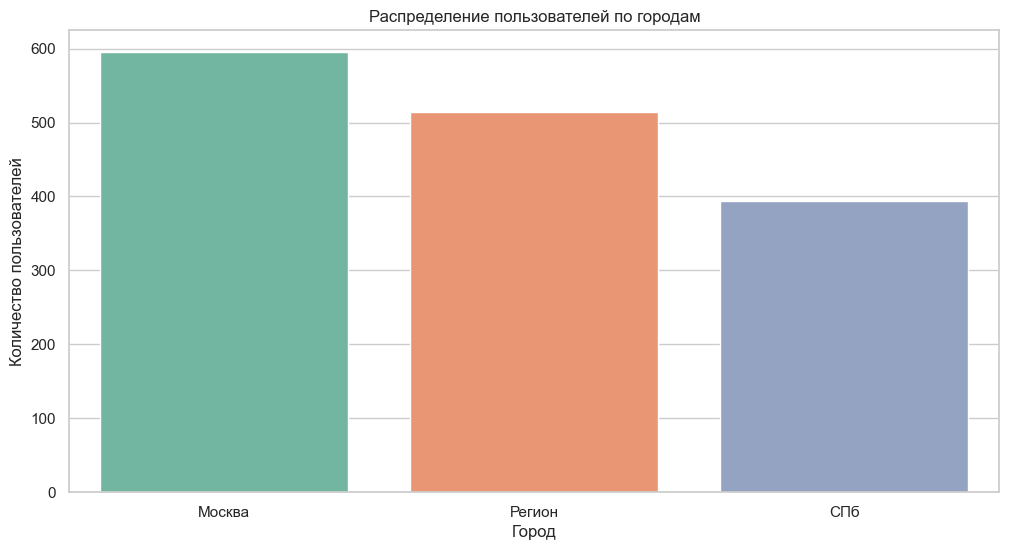

In [11]:
sns.set_theme(style="whitegrid", palette="Set2")
plt.figure(figsize=(12, 6))
sns.countplot(data=users, x='city', hue='city', legend=False)
plt.title("Распределение пользователей по городам")
plt.xlabel("Город")
plt.ylabel("Количество пользователей")  
plt.show()

**Признак *city* категориальный, имеет зн-я 'Москва', 'Регион', 'CПБ', но имеется один пропуск**

*device_type:*

In [12]:
users.device_type.value_counts().to_frame()

,count
device_type,
android,777
ios,727


**Признак *device_type* категориальный, имеет зн-я 'android' и 'ios'**

Посмотрим, есть ли вообще idишник с пропущенным group в таблице `payments`

In [13]:
mask = users['group'].isna()
id = users[mask]['user_id'].iloc[0] 
payments[payments["user_id"] == id].shape[0]

0

**Таблица `payments`**

In [14]:
#первичный скан
initial_scan(payments, "payments")

Initial scan of payments:
View:


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


Shape: (2661, 7)
Data types:



,Column,Data Type
0,payment_id,int64
1,user_id,float64
2,group,object
3,step1_opened,datetime64[ns]
4,step2_entered,datetime64[ns]
5,step3_confirmed,datetime64[ns]
6,step4_success,datetime64[ns]



 Quantity of Missing values:



,Column,Missing Values
0,payment_id,0
1,user_id,1
2,group,0
3,step1_opened,0
4,step2_entered,405
5,step3_confirmed,942
6,step4_success,1139



Quantity of duplicated rows: 0 


In [15]:
#есть ли дубликаты по payment_id
print(f"Кол-во дубликатов по payment_id: {payments.payment_id.duplicated().sum()}")

Кол-во дубликатов по payment_id: 0


По скану видно, что размер таблицы `payments` значительно больше, чем у таблицы `users`. Скорее всего, это связано с тем, что у одного пользователя может быть несколько попыток оплаты или же, есть пользователи, которые не попали в таблицу `users`. Проверим наши гипотезы:

Есть ли юзеры в платежах, которых нет в таблице users:

In [16]:
mask = payments['user_id'].isin(users['user_id'])
print(f'Количество пользователей, у которых нет записи в таблицы users: {(~mask).sum()}')

Количество пользователей, у которых нет записи в таблицы users: 1


Посмотрим, какой это user_id:

In [17]:
payments[~mask]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


В признаке user_id здесь пропуск, поэтому в очистке этот объект будет удален

Статистика платежей на одного юзера:

In [18]:
display(payments.groupby('user_id')['payment_id'].
        count().agg(['min', 'max', 'mean', 'median', 'std']).
        round(2).to_frame().reset_index().
        rename(columns={'index': 'Stats', 'payment_id': 'Payment Count'}))

,Stats,Payment Count
0,min,1.00
1,max,4.00
2,mean,1.77
3,median,2.00
4,std,0.90


Гипотеза, что у одного юзера может быть >1 платежа верна, аномалии в размеры таблицы нет. Значит таблицы `users` и `payments` относятся к друг другу, как 1 : M

Также проверим, есть ли юзеры, невключенные в таблицу `payments`:

In [19]:
mask = users['user_id'].isin(payments['user_id'])
print(f'Количество пользователей, у которых нет записи в таблицы payments: {(~mask).sum()}')

Количество пользователей, у которых нет записи в таблицы payments: 3


Посмотрим, какие это user_id:

In [20]:
users[~mask]

,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


По данным видно, что:
1. Аномальные id
2. В первом объекте отсутствует признак 'group'
3. Во 2 и 3 объектах аномальные значения возраста
Поэтому в очистке эти объекты будут удалены

`payment_id`

In [21]:
payments.payment_id.value_counts().sort_index()

payment_id
5001     1
5002     1
5003     1
5004     1
5005     1
        ..
7657     1
7658     1
99001    1
99002    1
99003    1
Name: count, Length: 2661, dtype: int64

**Видно, что payment_id идут последовательно(5001-7658), есть только три payment_id, которые отличаются: 99001, 99002, 9003**

`user_id`

In [22]:
payments.user_id.value_counts().sort_index()

user_id
1001.0    1
1002.0    1
1003.0    1
1004.0    3
1005.0    2
         ..
2497.0    1
2498.0    1
2499.0    3
2500.0    1
9004.0    1
Name: count, Length: 1501, dtype: int64

`group`

In [23]:
payments.group.value_counts()

group
B    1352
A    1309
Name: count, dtype: int64

Признаки `steps`:
Пропуски в них не случайны, так как не все пользователи доходят до конца оплаты. Проверим:
1. Все ли шаги в пределах 1-30 апреля 2024 года
2. Есть ли непоследовательность по времени(например: 3 шаг закончился раньше, чем 2)
3. Нет ли перепрыжек(например с 1 степа сразу на 3)

In [24]:
#1
steps = ["step1_opened", "step2_entered", "step3_confirmed", "step4_success"]
payments[steps].agg(["min", "max"])

,step1_opened,step2_entered,step3_confirmed,step4_success
min,2024-04-01 00:19:00,2024-04-01 00:23:00,2024-04-01 00:29:00,2024-04-01 00:33:00
max,2024-04-30 23:17:00,2024-04-30 23:20:00,2024-04-30 23:25:00,2024-04-30 23:30:00


Все шаги в пределах 1-30 апреля 2024 года

In [25]:
#2
bad_order = (
    (payments["step2_entered"]   < payments["step1_opened"]) |
    (payments["step3_confirmed"] < payments["step2_entered"]) |
    (payments["step4_success"]   < payments["step3_confirmed"])
)

print(f"Кол-во непоследовательности по времени: {bad_order.sum()}")

Кол-во непоследовательности по времени: 0


In [26]:
#3
skip = (
    (payments["step2_entered"].notna()   & payments["step1_opened"].isna()) |
    (payments["step3_confirmed"].notna() & payments["step2_entered"].isna()) |
    (payments["step4_success"].notna()   & payments["step3_confirmed"].isna())
)

print(f"Кол-во пропущенных шагов: {skip.sum()}")

Кол-во пропущенных шагов: 0


**Никаких ошибок в шагах не наблюдается**

**Вывод по EDA:** 

1. Объём и структура. Таблица users содержит 1504 строки и 5 признаков, payments 2661 строку и 7 признаков. Дубликатов строк нет, payment_id уникальны. Таблицы связаны как 1:M: у одного пользователя от 1 до 4 платежей, в среднем 1,77 (медиана 2).
2. Пользователи. Группы A и B примерно равны по размеру (752 и 751, у одного пользователя группа не указана). Возраст в основной массе от 20 до 60 лет, медиана 33 года. Города распределены как Москва 595, Регион 514, СПб 394, устройства как android 777 и ios 727.
3. Воронка и даты. Все шаги оплаты приходятся на 1-30 апреля 2024, порядок шагов не нарушен, «перепрыгнутых» шагов нет. Пропуски в step2-step4 объясняются тем, что часть пользователей не дошла до конца воронки, и ошибкой данных не являются:
4. Выявленные проблемы.
Один пользователь без группы (9001).
Два невозможных значения возраста: -5 (9002) и 150 (9003).
Один пропуск в городе (9004).
Один платёж без user_id (99003).
Три пользователя без платежей (9001-9003).
5. Нетипичные идентификаторы: user_id 9001-9004 при основной нумерации 1001-2500 и payment_id 99001-99003 при основной нумерации 5001-7658.
6. Что делаем дальше:
    1. Очистка: удаляем записи с невозможными значениями и без обязательных полей (группа, user_id), пропуск в городе заполняем значением Unknown.
    2. Feature engineering: считаем время между шагами воронки (step1_2, step2_3, step3_4, full_time, в минутах) и флаги достижения каждого шага (reached_step2-reached_step4, suc_flag). Пропуски во времени не заполняются, потому что они означают, что пользователь не дошёл до шага.


***Работа с выбросами, некорректными записями и feature engeneering***

**users:**

In [27]:
def users_clean(df, payments):
    df = df.copy()
    n_before = len(df)
    removed = {}                     
    filled = {}                     

    # 1. невозможный возраст
    bad_age = (df['age'] < 14) | (df['age'] > 100)
    removed['bad_age'] = df.loc[bad_age, 'user_id'].tolist()
    df = df[~bad_age].copy()

    # 2. пустая группа: пробуем восстановить по payments, иначе удаляем
    pay_group = (payments.dropna(subset=['user_id'])
                         .astype({'user_id': 'int64'})
                         .drop_duplicates('user_id')
                         .set_index('user_id')['group'])
    no_group = df['group'].isna()
    df.loc[no_group, 'group'] = df.loc[no_group, 'user_id'].map(pay_group)

    still_no_group = df['group'].isna()
    removed['no_group'] = df.loc[still_no_group, 'user_id'].tolist()
    df = df[~still_no_group].copy()

    # 3. пропуск в городе -> 'Unknown'
    no_city = df['city'].isna()
    filled['city_unknown'] = df.loc[no_city, 'user_id'].tolist()
    df['city'] = df['city'].fillna('Unknown')

    removed_ids = [uid for ids in removed.values() for uid in ids]   # плоский список

    print(f"Было: {n_before}, стало: {len(df)}, удалено: {len(removed_ids)}")
    for reason, ids in removed.items():
        print(f"  удалено ({reason}): {ids}")
    for reason, ids in filled.items():
        print(f"  заполнено ({reason}): {ids}")
    return df, removed_ids

In [28]:
users_fix, removed_ids = users_clean(users, payments)

Было: 1504, стало: 1501, удалено: 3
  удалено (bad_age): [9002, 9003]
  удалено (no_group): [9001]
  заполнено (city_unknown): [9004]


**payments:**

Посмотрим, есть ли объекты в payments, которые мы исключили из таблицы users:

In [29]:
payments[payments['user_id'].isin(removed_ids)].shape[0]

0

Удалим объект с неизвестным user_id и сделаем user_id интовым:

In [30]:
payments_fix = payments.dropna(subset=['user_id']).copy()
payments_fix['user_id'] = payments_fix['user_id'].astype('int64')
print(f"Удалено объектов: {payments.shape[0] - payments_fix.shape[0]}")
print(f"Удаленный payment_id: {payments.loc[payments['user_id'].isna(), 'payment_id'].item()}")

Удалено объектов: 1
Удаленный payment_id: 99003


**feature_engeneering в payments**

Создадим признаки, отражающее время перехода между шагами и итоговое время оформления платежа:

In [31]:
payments_fix['step1_2'] = (payments_fix['step2_entered'] - payments_fix['step1_opened']).dt.total_seconds() / 60
payments_fix['step2_3'] = (payments_fix['step3_confirmed'] - payments_fix['step2_entered']).dt.total_seconds() / 60
payments_fix['step3_4'] = (payments_fix['step4_success'] - payments_fix['step3_confirmed']).dt.total_seconds() / 60
payments_fix['full_time'] = (payments_fix['step4_success'] - payments_fix['step1_opened']).dt.total_seconds() / 60

In [32]:
payments_fix.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,step1_2,step2_3,step3_4,full_time
0,5001,1001,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT,4.0,NaN,NaN,NaN
1,5002,1002,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT,3.0,NaN,NaN,NaN
2,5003,1003,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT,4.0,NaN,NaN,NaN
3,5004,1004,A,2024-04-09 16:02:00,NaT,NaT,NaT,NaN,NaN,NaN,NaN
4,5005,1004,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00,8.0,3.0,5.0,16.0


Посмотрим на статистистические показатели времени переходов:

In [33]:
steps_time = ['step1_2', 'step2_3', 'step3_4', 'full_time']
payments_fix[steps_time].describe().round(2)

,step1_2,step2_3,step3_4,full_time
count,2256.00,1719.00,1522.00,1522.00
mean,2.39,4.49,5.48,12.38
std,1.86,1.92,1.06,2.81
min,1.00,1.00,1.00,5.00
25%,1.00,3.00,5.00,10.00
50%,1.00,4.00,6.00,12.00
75%,3.00,6.00,6.00,14.00
max,13.00,11.00,9.00,24.00


Создадим флаги, какие шаги платежа дошел user:

In [34]:
payments_fix['reached_step1'] = payments_fix['step1_opened'].notna()
payments_fix['reached_step2'] = payments_fix['step2_entered'].notna()
payments_fix['reached_step3'] = payments_fix['step3_confirmed'].notna()
payments_fix['reached_step4'] = payments_fix['step4_success'].notna()

In [35]:
payments_fix.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,step1_2,step2_3,step3_4,full_time,reached_step1,reached_step2,reached_step3,reached_step4
0,5001,1001,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT,4.0,NaN,NaN,NaN,True,True,False,False
1,5002,1002,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT,3.0,NaN,NaN,NaN,True,True,False,False
2,5003,1003,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT,4.0,NaN,NaN,NaN,True,True,False,False
3,5004,1004,A,2024-04-09 16:02:00,NaT,NaT,NaT,NaN,NaN,NaN,NaN,True,False,False,False
4,5005,1004,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00,8.0,3.0,5.0,16.0,True,True,True,True


Проверим согласованность таблиц. Группа пользователя указана и в users, и в payments. Они должны совпадать. Объединим таблицы и сравним.

In [36]:
check = users_fix.merge(payments_fix, on='user_id', how='left', suffixes=('_users', '_pay'))
mismatch = check['group_users'] != check['group_pay']
print(f"Несовпадений группы: {mismatch.sum()}")
display(check[mismatch])

Несовпадений группы: 1


,user_id,group_users,age,city,device_type,payment_id,group_pay,step1_opened,step2_entered,step3_confirmed,step4_success,step1_2,step2_3,step3_4,full_time,reached_step1,reached_step2,reached_step3,reached_step4
16,1010,A,26,Москва,android,99002,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,3.0,5.0,1.0,9.0,True,True,True,True


Удаляем пользователя из анализа.

In [37]:
mask = users_fix['user_id'] == check.loc[mismatch, 'user_id'].iloc[0]
users_fix = users_fix.drop(index=users_fix[mask].index)


In [38]:
mask = payments_fix['user_id'] == check.loc[mismatch, 'user_id'].iloc[0]
payments_fix = payments_fix.drop(index=payments_fix[mask].index)

In [39]:
print(f'из обеих групп удален пользователь с id: {check.loc[mismatch, 'user_id'].iloc[0]}')
r = payments[payments['user_id'] == check.loc[mismatch, 'user_id'].iloc[0]]
print(f'Кол-во удаленных объектов в таблице payments в связи с удалением этого пользователя: {r.shape[0]}')
print(f'payment_id этих объектов: {r['payment_id'].tolist()}')

из обеих групп удален пользователь с id: 1010
Кол-во удаленных объектов в таблице payments в связи с удалением этого пользователя: 2
payment_id этих объектов: [5015, 99002]


In [61]:
#посмотрим оставшиеся аномальные значения по payments_id
payments_fix['payment_id'].value_counts().sort_index()

payment_id
5001     1
5002     1
5003     1
5004     1
5005     1
        ..
7655     1
7656     1
7657     1
7658     1
99001    1
Name: count, Length: 2658, dtype: int64

In [64]:
#посмотрим на объект с payment_id = 99001
payments_fix[payments_fix['payment_id'] == 99001]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,step1_2,step2_3,step3_4,full_time,reached_step1,reached_step2,reached_step3,reached_step4
2658,99001,1005,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00,3.0,5.0,1.0,9.0,True,True,True,True


Других анамальных значений не найдено, поэтому не исключаем объект с payment_id = 99001

Итого: размеры очищенных таблиц:

In [40]:
print(f"users:    {users.shape} -> {users_fix.shape}, удалено {len(users) - len(users_fix)} "
      f"({(len(users) - len(users_fix)) / len(users):.2%})")
print(f"payments: {payments.shape} -> {payments_fix.shape}, удалено {len(payments) - len(payments_fix)} "
      f"({(len(payments) - len(payments_fix)) / len(payments):.2%})")

users:    (1504, 5) -> (1500, 5), удалено 4 (0.27%)
payments: (2661, 7) -> (2658, 15), удалено 3 (0.11%)


### Итоги предобработки данных

#### `users`
* **Исключены 4 объекта:**
  * `user_id = 9001` — отсутствовала группа.
  * `user_id = 9002` и `user_id = 9003` — аномальный возраст.
  * `user_id = 1010` — данные по группам разошлись между таблицами `users` и `payments`.
* **Заполнение пропусков:** 
  * Для `user_id = 9004` пропуск в признаке «город» заменен на `Unknown`. Несмотря на аномальность ID, веских аргументов для полного удаления объекта не найдено.

#### `payments`
* **Удалены некорректные объекты:**
  * `payment_id = 99003` — неизвестный `user_id`.
  * `payment_id = 5015` и `payment_id = 99002` — объекты для `user_id = 1010`, у которого разошлись данные по группам с таблицей `users`.
* **Сохраненные аномалии:**
  * `payment_id = 99001` — объект оставлен, так как других аномальных признаков в нем не обнаружено.


In [66]:
#Сделаем проверку по согласованности:
print((~payments_fix['user_id'].isin(users_fix['user_id'])).sum())   # платежи без пользователя
print((~users_fix['user_id'].isin(payments_fix['user_id'])).sum())   # пользователи без платежей

0
0


**Теперь мы мерджим 2 таблицы и оставляем самый успешный платеж  юзера**

In [67]:
r_steps = ['reached_step1','reached_step2',	'reached_step3','reached_step4']
payments_fix_suc = payments_fix.groupby('user_id')[r_steps].max().reset_index() #то есть смотрим, до какого шага максимум дошел user
payments_fix_suc

,user_id,reached_step1,reached_step2,reached_step3,reached_step4
0,1001,True,True,False,False
1,1002,True,True,False,False
2,1003,True,True,False,False
3,1004,True,True,True,True
4,1005,True,True,True,True
...,...,...,...,...,...
1495,2497,True,False,False,False
1496,2498,True,True,True,True
1497,2499,True,True,True,True
1498,2500,True,True,False,False


In [68]:
user_table = payments_fix_suc.reset_index().merge(
    users_fix, on='user_id', how='left'
)

#сразу проверим 
display(user_table.head())   
print(user_table.shape)                        
print(user_table['user_id'].is_unique)      
print(user_table['group'].isna().sum())      
print(user_table['group'].value_counts())
print(user_table.groupby('group')['reached_step4'].mean().round(4))

,index,user_id,reached_step1,reached_step2,reached_step3,reached_step4,group,age,city,device_type
0,0,1001,True,True,False,False,A,31,Москва,ios
1,1,1002,True,True,False,False,A,31,Москва,ios
2,2,1003,True,True,False,False,A,25,Москва,android
3,3,1004,True,True,True,True,A,20,Москва,ios
4,4,1005,True,True,True,True,A,34,Москва,ios


(1500, 10)
True
0
group
A    750
B    750
Name: count, dtype: int64
group
A    0.6573
B    0.8040
Name: reached_step4, dtype: float64


**Проверим баланс групп:**

1. Разбиение на тестовые группы:

In [69]:
import scipy.stats as stats
def check_srm(A_group_size, B_group_size):
    expected_ratios = [0.5, 0.5]
    observed_counts = [A_group_size, B_group_size]
    
    chi2_stat, p_value = stats.chisquare(observed_counts, f_exp=[sum(observed_counts) * r for r in expected_ratios])
    
    print(f"χ²: {chi2_stat:.4f}")
    print(f"P-value: {p_value:.4f}")
    
  

In [70]:
gr = user_table['group'].value_counts()
check_srm(gr['A'], gr['B'])

χ²: 0.0000
P-value: 1.0000


SRM-проверка: χ² = 0,00, p = 1,00. Группы совпадают по размеру (750 и 750), перекоса нет, рандомизация корректна.

2. Разбиение на типы_устройств:

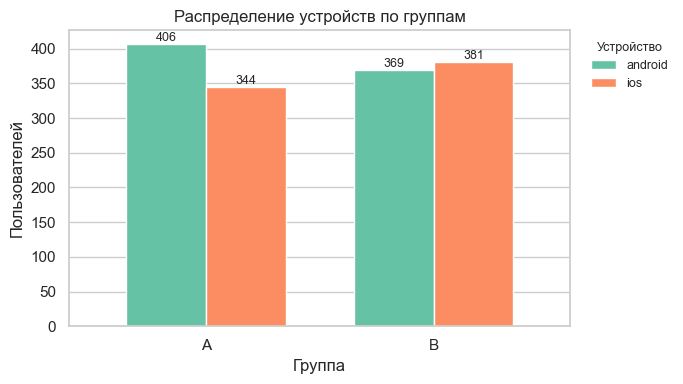

In [49]:
dev = pd.crosstab(user_table['group'], user_table['device_type'])

ax = dev.plot(kind='bar', figsize=(7, 4), width=0.7)
ax.set_title("Распределение устройств по группам")
ax.set_xlabel("Группа")
ax.set_ylabel("Пользователей")
ax.set_xticklabels(dev.index, rotation=0)
ax.grid(axis='x', visible=False)
ax.legend(title="Устройство", fontsize=9, title_fontsize=9,
          bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
for c in ax.containers:
    ax.bar_label(c, fontsize=9)
plt.tight_layout()
plt.show()


По графику имеются различия. В группе A преобладают устройства android, а в группе B немного больше устройств ios

In [50]:
from scipy.stats import chi2_contingency
chi2, p, dof, exp = chi2_contingency(dev)
print(dev)
print(f"p-value: {p:.4f}")

device_type  android  ios
group                    
A                406  344
B                369  381
p-value: 0.0629


Проверка: p_value = 0,0629 > 0,05 -> перекоса нет, рандомизация корректна. Однако после z-теста посмотрим, не влияют ли на конверсию различия устройсв

Разбиение на города:

In [51]:
city = pd.crosstab(user_table['group'], user_table['city']).drop(columns='Unknown', errors='ignore')
chi2, p, dof, exp = chi2_contingency(city)
print(city)
print(f"p-value: {p:.4f}")

city   Москва  Регион  СПб
group                     
A         287     268  194
B         306     245  199
p-value: 0.4268


Проверка: p_value = 0,4268 > 0,05 -> перекоса нет, рандомизация корректна.

Разбиения по возасту:

In [52]:
from scipy.stats import mannwhitneyu

a_age = user_table.loc[user_table['group'] == 'A', 'age']
b_age = user_table.loc[user_table['group'] == 'B', 'age']
print(user_table.groupby('group')['age'].describe().round(2))
print(f"p-value: {mannwhitneyu(a_age, b_age).pvalue:.4f}")

       count   mean   std   min   25%   50%   75%   max
group                                                  
A      750.0  32.75  7.82  20.0  27.0  32.0  38.0  60.0
B      750.0  32.65  7.78  20.0  27.0  33.0  38.0  60.0
p-value: 0.8399


Проверка: p_value = 0,8399 > 0,05 -> перекоса нет, рандомизация корректна.

**Воронка:**

Посмотрим, статистику переходов у каждой группы

In [53]:
user_table.groupby('group')[r_steps].mean()

,reached_step1,reached_step2,reached_step3,reached_step4
group,,,,
A,1.0,0.894667,0.730667,0.657333
B,1.0,0.942667,0.858667,0.804000


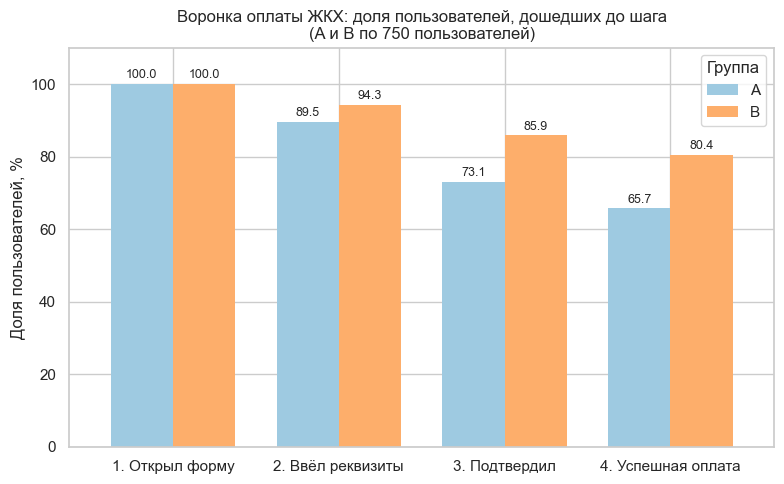

In [54]:
funnel = (user_table.groupby('group')[r_steps].mean() * 100).T

ax = funnel.plot(kind='bar', figsize=(8, 5),
                 color={"A": "#9ecae1", "B": "#fdae6b"},
                 width=0.75, edgecolor='none')

ax.set_title("Воронка оплаты ЖКХ: доля пользователей, дошедших до шага\n(A и B по 750 пользователей)")
ax.set_ylabel("Доля пользователей, %")
ax.set_xlabel("")
ax.set_xticklabels(["1. Открыл форму", "2. Ввёл реквизиты",
                    "3. Подтвердил", "4. Успешная оплата"], rotation=0)
ax.set_ylim(0, 110)
ax.legend(title="Группа")
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', padding=2, fontsize=9)
plt.tight_layout()
plt.show()

Видно, что конверсия у группы B по сравненению с группой A значительно увеличилась, проведем z test:

In [ ]:
# 4. условие применимости z-теста: n*p > 10 и n*(1-p) > 10 для каждой группы
#    n — размер группы (количество пользователей)
#    p — доля успехов в группе (конверсия reached_step4)
print("\nУсловие применимости z-теста (n*p > 10 и n*(1-p) > 10):")
for g in ['A', 'B']:
    n = (user_table['group'] == g).sum()
    p = user_table.loc[user_table['group'] == g, 'reached_step4'].mean()
    np_, nq_ = n * p, n * (1 - p)
    print(f"  {g}: n={n} (размер группы), p={p:.4f} (доля успехов), "
          f"n*p={np_:.1f} (ожидаемое число успехов), n*(1-p)={nq_:.1f} (ожидаемое число неудач)")
    assert np_ > 10 and nq_ > 10, f"условие не выполняется для группы {g}"




Условие применимости z-теста (n*p > 10 и n*(1-p) > 10):
  A: n=750 (размер группы), p=0.6573 (доля успехов), n*p=493.0 (ожидаемое число успехов), n*(1-p)=257.0 (ожидаемое число неудач)
  B: n=750 (размер группы), p=0.8040 (доля успехов), n*p=603.0 (ожидаемое число успехов), n*(1-p)=147.0 (ожидаемое число неудач)

Все условия для z-теста пропорций выполнены.


**Обоснование теста.** Метрика — доля дошедших до шага 4 на пользователя (0/1), поэтому используется z-тест пропорций.

H0: pA = pB. H1: pB > pA (по направлению гипотезы задания). α = 0.05.

Предпосылки выполнены: наблюдения независимы (одна строка на пользователя), группы не пересекаются (user 1010 с противоречивой группой удалён при очистке), n·p и n·(1−p) > 10 для обеих групп.

Если p-value < α — отвергаем H0.

In [72]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

counts = user_table.groupby('group')['reached_step4'].sum().values    # успехи: [A, B]
nobs   = user_table.groupby('group')['reached_step4'].count().values  # всего:  [A, B]

# H0: pA = pB, H1: pA < pB (т.е. pB > pA) — односторонний тест, как в markdown
stat, pval = proportions_ztest(counts, nobs, alternative='smaller')
ci_low, ci_upp = confint_proportions_2indep(counts[1], nobs[1], counts[0], nobs[0], method='wald')

pA, pB = counts[0] / nobs[0], counts[1] / nobs[1]

print(f"A: {counts[0]}/{nobs[0]} = {pA:.2%}")
print(f"B: {counts[1]}/{nobs[1]} = {pB:.2%}")
print(f"Разница (B - A): {(pB - pA) * 100:.2f} п.п.  (относительный рост {(pB / pA - 1) * 100:.1f}%)")
print(f"H1: pB > pA (односторонний тест)")
print(f"z = {stat:.3f}, p-value = {pval:.3e}")
print(f"95% ДИ для разницы: [{ci_low * 100:.2f}; {ci_upp * 100:.2f}] п.п.")

alpha = 0.05
if pval < alpha:
    print(f"\np-value < α ({alpha}) → отвергаем H0, конверсия B статистически значимо выше A")
else:
    print(f"\np-value >= α ({alpha}) → не отвергаем H0")

A: 493/750 = 65.73%
B: 603/750 = 80.40%
Разница (B - A): 14.67 п.п.  (относительный рост 22.3%)
H1: pB > pA (односторонний тест)
z = -6.402, p-value = 7.648e-11
95% ДИ для разницы: [10.24; 19.09] п.п.

p-value < α (0.05) → отвергаем H0, конверсия B статистически значимо выше A


**Результат.** Конверсия в группе B выше, чем в A, 80.40% (603 из 750) против 65.73% (493 из 750). Разница +14.67 п.п., относительный рост 22.3%.

Односторонний z-тест пропорций: z = -6.40, p-value ≈ 7.6×10⁻¹¹, что намного меньше α = 0.05. H0 отвергается — конверсия B статистически значимо выше A.

95% ДИ для разницы: [10.24; 19.09] п.п. — эффект не только значим, но и практически большой.

*Распределение устройств между группами оказалось на границе значимости (p = 0,06): в A немного больше Android, в B немного больше iOS. Нужно убедиться, что прирост конверсии объясняется новой формой, а не этим перекосом. Для этого посчитаем конверсию отдельно внутри каждого типа устройства.*

In [73]:
user_table.groupby(['device_type', 'group'])['reached_step4'].agg(['sum', 'count', 'mean']).round(4)

sum  count    mean
device_type group                    
android     A      262    406  0.6453
            B      295    369  0.7995
ios         A      231    344  0.6715
            B      308    381  0.8084

Эффект сохраняется в обоих срезах. На Android 64,5 % против 80,0 % (+15,4 п.п.), на iOS 67,2 % против 80,8 % (+13,7 п.п.). Направление и величина совпадают с общим результатом.

**Проверка различия  времени прохождения шагов между группами**

In [93]:
step_cols = ['step1_2', 'step2_3', 'step3_4', 'full_time']

best_attempt = (
    payments_fix
    .sort_values(
        ['user_id', 'reached_step4', 'reached_step3', 'reached_step2', 'reached_step1', 'step1_opened'],
        ascending=[True, False, False, False, False, True]
    )
    .groupby('user_id')
    .first()[step_cols]
    .reset_index()
)

user_table = user_table.merge(best_attempt, on='user_id', how='left')

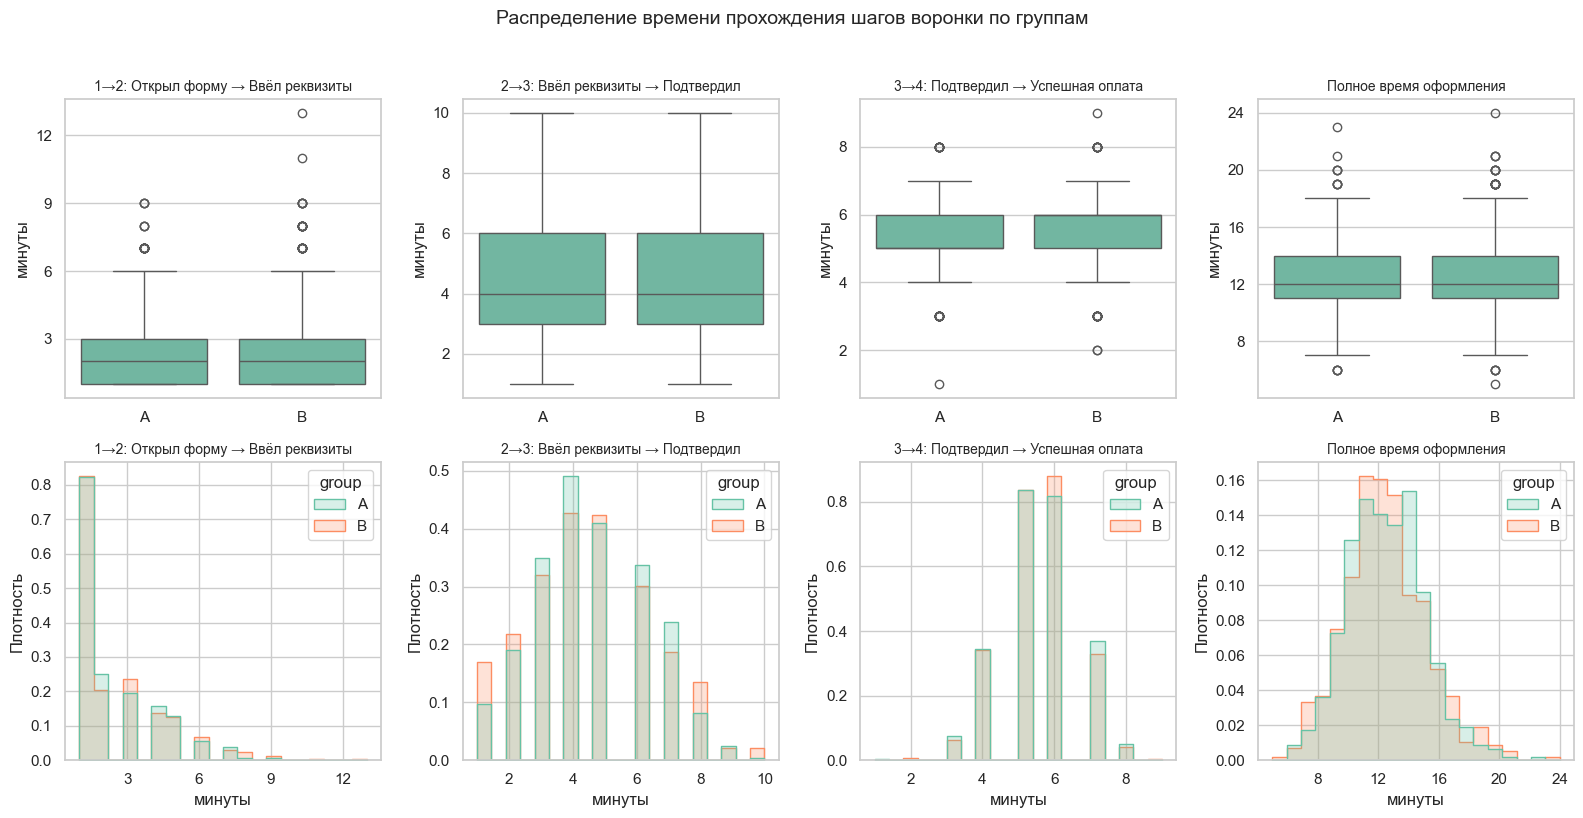

In [94]:
import matplotlib.ticker as mticker

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

titles = {
    'step1_2': '1→2: Открыл форму → Ввёл реквизиты',
    'step2_3': '2→3: Ввёл реквизиты → Подтвердил',
    'step3_4': '3→4: Подтвердил → Успешная оплата',
    'full_time': 'Полное время оформления',
}

for i, col in enumerate(steps_time):
    sns.boxplot(data=user_table, x='group', y=col, ax=axes[0, i])
    axes[0, i].set_title(titles[col], fontsize=10)
    axes[0, i].set_xlabel('')
    axes[0, i].set_ylabel('минуты')
    axes[0, i].yaxis.set_major_locator(mticker.MaxNLocator(nbins=6, integer=True))

    sns.histplot(data=user_table, x=col, hue='group', bins=20,
                 element='step', stat='density', common_norm=False, ax=axes[1, i])
    axes[1, i].set_title(titles[col], fontsize=10)
    axes[1, i].set_xlabel('минуты')
    axes[1, i].set_ylabel('Плотность')
    axes[1, i].xaxis.set_major_locator(mticker.MaxNLocator(nbins=6, integer=True))

fig.suptitle('Распределение времени прохождения шагов воронки по группам',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Проверка распределения.** Боксплоты и гистограммы показывают, что время переходов не распределено нормально: `step1_2` сильно скошено вправо с длинным хвостом, у `step3_4` и `full_time` есть отдельные выбросы за пределами усов боксплота. Данные дискретны (целые минуты) и ограничены снизу нулём.

**Гипотезы.** H0: распределения времени перехода одинаковы в группах A и B. H1: распределения различаются (двусторонняя альтернатива). α = 0.05.

Метрика непрерывная (минуты), но распределение скошено и с выбросами (см. графики выше), поэтому вместо t-теста используется критерий Манна — Уитни.

In [95]:
from scipy.stats import mannwhitneyu

results = []
for col in steps_time:
    a = user_table.loc[user_table['group'] == 'A', col].dropna()
    b = user_table.loc[user_table['group'] == 'B', col].dropna()
    u, p = mannwhitneyu(a, b, alternative='two-sided')
    results.append({
        'Переход': col,
        'Медиана A': a.median(),
        'Медиана B': b.median(),
        'n (A/B)': f"{len(a)}/{len(b)}",
        'U': int(u),
        'p-value': round(p, 4),
    })

mw_results = pd.DataFrame(results)
display(mw_results)

,Переход,Медиана A,Медиана B,n (A/B),U,p-value
0,step1_2,2.0,2.0,671/707,234366,0.6815
1,step2_3,4.0,4.0,548/644,180971,0.4405
2,step3_4,5.0,6.0,493/603,148916,0.9559
3,full_time,12.0,12.0,493/603,151761,0.5467


**Вывод.** Время прохождения шагов между группами не различается: p-value на всех переходах намного больше α = 0.05 (от 0.44 до 0.95), медианы совпадают. H0 не отвергается.

Значит, новая форма не ускоряет оформление платежа, так как люди тратят то же время. Эффект объясняется не скоростью, а тем, что меньше пользователей бросает на переходе «ввёл реквизиты → подтвердил».


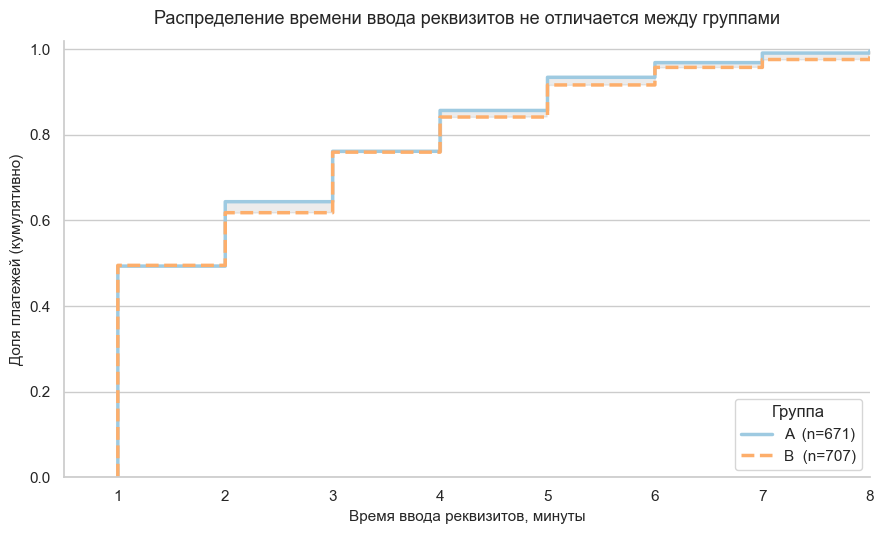

In [101]:
a = user_table.loc[user_table['group'] == 'A', 'step1_2'].dropna()
b = user_table.loc[user_table['group'] == 'B', 'step1_2'].dropna()

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = {"A": "#9ecae1", "B": "#fdae6b"}
styles = {"A": "-", "B": "--"}
curves = {}

for g, s in [('A', a), ('B', b)]:
    s = s.sort_values().values
    y = np.arange(1, len(s) + 1) / len(s)
    ax.step(s, y, where='post', label=f"{g}  (n={len(s)})",
            color=colors[g], lw=2.5, linestyle=styles[g])
    curves[g] = (s, y)

x_common = np.linspace(1, 8, 300)
y_a = np.interp(x_common, curves['A'][0], curves['A'][1])
y_b = np.interp(x_common, curves['B'][0], curves['B'][1])
ax.fill_between(x_common, y_a, y_b, color='gray', alpha=0.15, step='mid')

ax.set_xlim(0.5, 8)
ax.set_ylim(0, 1.02)
ax.set_xlabel('Время ввода реквизитов, минуты', fontsize=11)
ax.set_ylabel('Доля платежей (кумулятивно)', fontsize=11)
ax.set_title('Распределение времени ввода реквизитов не отличается между группами',
             fontsize=13, pad=12)

ax.legend(title='Группа', loc='lower right')
ax.grid(axis='x', visible=False)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

**Вывод.** Кривые ECDF для шага ввода реквизитов у групп A и B почти полностью совпадают, расхождение минимально. Это подтверждает результат теста Манна — Уитни (см. p-value выше): различий во времени ввода реквизитов между группами нет.

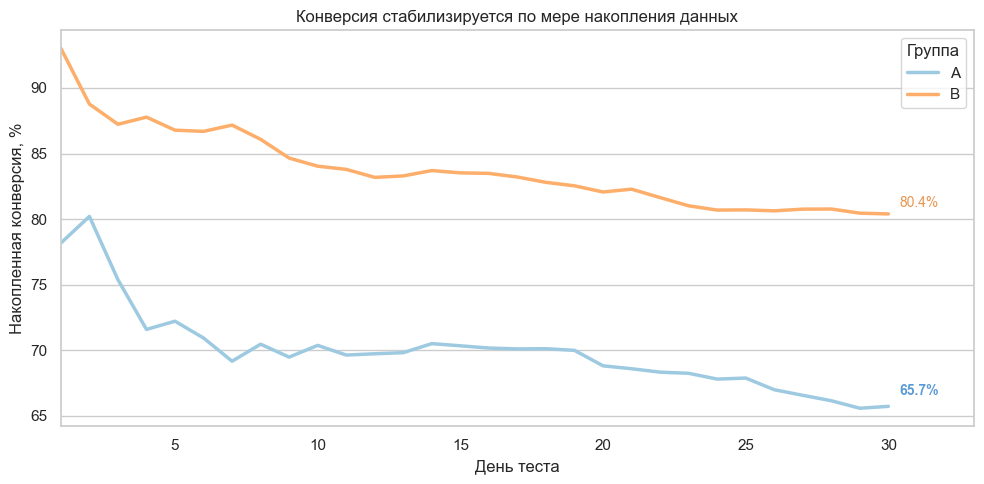

In [108]:
first_try = payments_fix.groupby('user_id')['step1_opened'].min()
w = user_table.assign(start=user_table['user_id'].map(first_try))

daily = w.copy()
daily['day'] = (daily['start'] - pd.Timestamp('2024-04-01')).dt.days + 1

days = range(1, 31)
cum = {'A': [], 'B': []}
for d in days:
    for g in ['A', 'B']:
        sub = daily[(daily['day'] <= d) & (daily['group'] == g)]
        cum[g].append(sub['reached_step4'].mean() * 100)

fig, ax = plt.subplots(figsize=(10, 5))

for g, color in [('A', "#9ecae1"), ('B', "#fdae6b")]:
    ax.plot(list(days), cum[g], color=color, lw=2.5, label=g)


ax.annotate(f"{cum['B'][-1]:.1f}%", (30, cum['B'][-1]), xytext=(8, 5),
            textcoords="offset points", fontsize=10, color="#e8954f")
ax.annotate(f"{cum['A'][-1]:.1f}%", (30, cum['A'][-1]), xytext=(8, 8),
            textcoords="offset points", fontsize=10, color="#5b9bd5",
            fontweight='bold')

ax.set_xlabel('День теста')
ax.set_ylabel('Накопленная конверсия, %')
ax.set_title('B стабильно опережает A на всём протяжении теста')
ax.set_xlim(1, 33)
ax.legend(title='Группа', loc='upper right')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

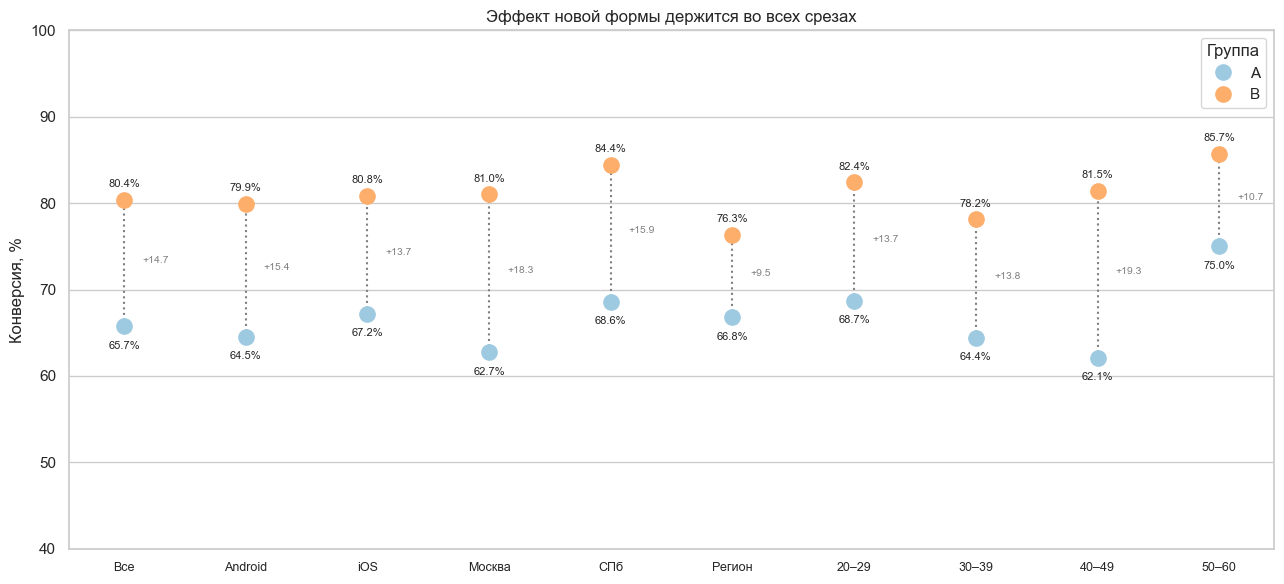

In [109]:
user_table['age_group'] = pd.cut(
    user_table['age'],
    bins=[19, 29, 39, 49, 61],
    labels=['20–29', '30–39', '40–49', '50–60']
)

segments = {
    'Все': user_table,
    'Android': user_table[user_table['device_type'] == 'android'],
    'iOS': user_table[user_table['device_type'] == 'ios'],
    'Москва': user_table[user_table['city'] == 'Москва'],
    'СПб': user_table[user_table['city'] == 'СПб'],
    'Регион': user_table[user_table['city'] == 'Регион'],
    '20–29': user_table[user_table['age_group'] == '20–29'],
    '30–39': user_table[user_table['age_group'] == '30–39'],
    '40–49': user_table[user_table['age_group'] == '40–49'],
    '50–60': user_table[user_table['age_group'] == '50–60'],
}

rows = []
for name, sub in segments.items():
    conv = sub.groupby('group')['reached_step4'].mean() * 100
    rows.append({'segment': name, 'A': conv.get('A', np.nan), 'B': conv.get('B', np.nan)})

seg_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(13, 6))
x = range(len(seg_df))

ax.plot(x, seg_df['A'], 'o', color="#9ecae1", ms=11, zorder=3, label='A')
ax.plot(x, seg_df['B'], 'o', color="#fdae6b", ms=11, zorder=3, label='B')

for i, row in seg_df.iterrows():
    ax.vlines(i, row['A'], row['B'], color='gray', ls=':', lw=1.5)
    ax.annotate(f"{row['A']:.1f}%", (i, row['A']), xytext=(0, -16),
                textcoords="offset points", ha='center', fontsize=8)
    ax.annotate(f"{row['B']:.1f}%", (i, row['B']), xytext=(0, 9),
                textcoords="offset points", ha='center', fontsize=8)
    diff = row['B'] - row['A']
    ax.annotate(f"+{diff:.1f}", (i, (row['A'] + row['B']) / 2),
                xytext=(13, 0), textcoords="offset points", fontsize=7.5, color='gray')

ax.set_xticks(x)
ax.set_xticklabels(seg_df['segment'], fontsize=9)
ax.set_ylabel('Конверсия, %')
ax.set_title('Эффект новой формы держится во всех срезах')
ax.set_ylim(40, 100)
ax.legend(title='Группа', loc='upper right')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

## Вывод и рекомендация

Рекомендую масштабировать новую форму. Конверсия в успешную оплату статистически значимо выросла с 65,73% до 80,40%, то есть на 14,67 п.п. Основной выигрыш проявляется в снижении потерь между вводом реквизитов и подтверждением платежа.

Сначала включить форму для 90-95% пользователей, оставив контрольную группу 5-10% на две недели. Проверить отсутствие параллельных изменений и отслеживать конверсию, ошибочные платежи и обращения в поддержку. При сохранении эффекта и отсутствии ухудшений перейти на 100%.

### Возможное объяснение эффекта

Возможно, автозаполнение уменьшает число опечаток, которые приводят к отказу на этапе подтверждения. Пока это только предположение. Чтобы его проверить, нужно собирать данные о причинах отклонения платежей и о том, как часто пользователи исправляют введённые реквизиты.

### Открытый вопрос

Несмотря на автозаполнение, заметного сокращения времени ввода реквизитов не обнаружено. Медиана составляет 2 минуты в обеих группах, статистически значимых различий не выявлено (p = 0,6815).

Остаётся открытым вопрос, почему автозаполнение повысило конверсию, но не дало заметного ускорения. Стоит проверить, как часто пользователи применяют автозаполнение и нужны ли после него ручные исправления.